# SSI Analysis: soil moisture drought

**Aim.** Compute the Standardized Soil Moisture Index (SSI) for one district step by step, check that it behaves
as a standard normal index, describe soil-moisture droughts with run theory and a duration-severity copula, and
validate the SSI against rainfall (SPI) and the shared test droughts. The last sections
cover all 25 districts and what the rainfall-to-soil delay means for paddy.

Every number comes from the project's modules (`ssi_analysis.py`, `spi_copula_analysis.py`, `index_data.py`,
`compare_indices.py`, `model_checks.py`), so this notebook and the dashboard agree.

**Contents**
1. Data: GWETROOT soil moisture, climatology, comparison with rainfall
2. Distribution fitting per calendar month
3. SSI calculation and drought classes
4. Is the SSI standard normal?
5. Drought events, marginals, copula and return periods
6. Validation of the SSI against SPI and the shared test droughts
7. All 25 districts
8. How soil moisture lags rainfall, and what it means for paddy
9. Summary of findings
10. Limitations

**How to run.** Open from the project folder, change the settings cell if needed, then *Restart and Run All*
(about one to two minutes).

In [1]:
# Load the helpers, move to the project folder and apply the dashboard look
import nbtools as nt
nt.setup()

import calendar
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

import common
import theme

from ssi_analysis import compute_ssi, CANDIDATE_MARGINALS
import threshold_skill as TS
import thresholds as TH
from spi_copula_analysis import T_and, T_or, _copula_cdf, return_period_table
import compare_indices as CI
import index_data
import model_checks as mc

## Settings

In [2]:
DISTRICT = "Anuradhapura"        # any of the 25 districts
SCALE = 3                        # accumulation window in months: 1, 3 or 6
START_YEAR, END_YEAR = 1984, 2025  # years shown in the time-series plots (fits use the full record, as the dashboard does)
N_BOOT = 500                     # bootstrap samples for the Cramer-von Mises copula test

## 1. Data: GWETROOT soil moisture

GWETROOT is NASA POWER's root-zone soil wetness: the fraction of the available pore space in the top metre of
soil that is filled with water, from 0 (completely dry) to 1 (saturated). It has no units. The pipeline averages
it over the grid cells inside the district, as for rainfall.

$$\theta_{y,m} = \frac{1}{|G|}\sum_{g\in G}\theta_{g,y,m},\qquad 0 \le \theta \le 1$$

In [3]:
soil = common.read_soil(DISTRICT)
rain = common.read_rainfall(DISTRICT)
soil["Year"], soil["Month"] = soil["date"].dt.year, soil["date"].dt.month
both = soil.merge(rain[["Year", "Month", "prcp"]], on=["Year", "Month"])
print(f"{DISTRICT}: {len(soil)} months of GWETROOT, {soil['date'].min():%b %Y} to {soil['date'].max():%b %Y}, "
      f"from {int(soil['n_cells'].iloc[0])} grid cell(s)")
nt.show(both[["date", "gwetroot", "prcp"]].rename(columns={"gwetroot": "soil wetness (0-1)", "prcp": "rainfall (mm)"}), n=6)

Anuradhapura: 504 months of GWETROOT, Jan 1984 to Dec 2025, from 2 grid cell(s)


,date,soil wetness (0-1),rainfall (mm)
0,1984-01-01,0.975,355.260
1,1984-02-01,0.980,326.250
2,1984-03-01,0.925,169.415
3,1984-04-01,0.885,301.050
4,1984-05-01,0.845,47.895
5,1984-06-01,0.705,22.050


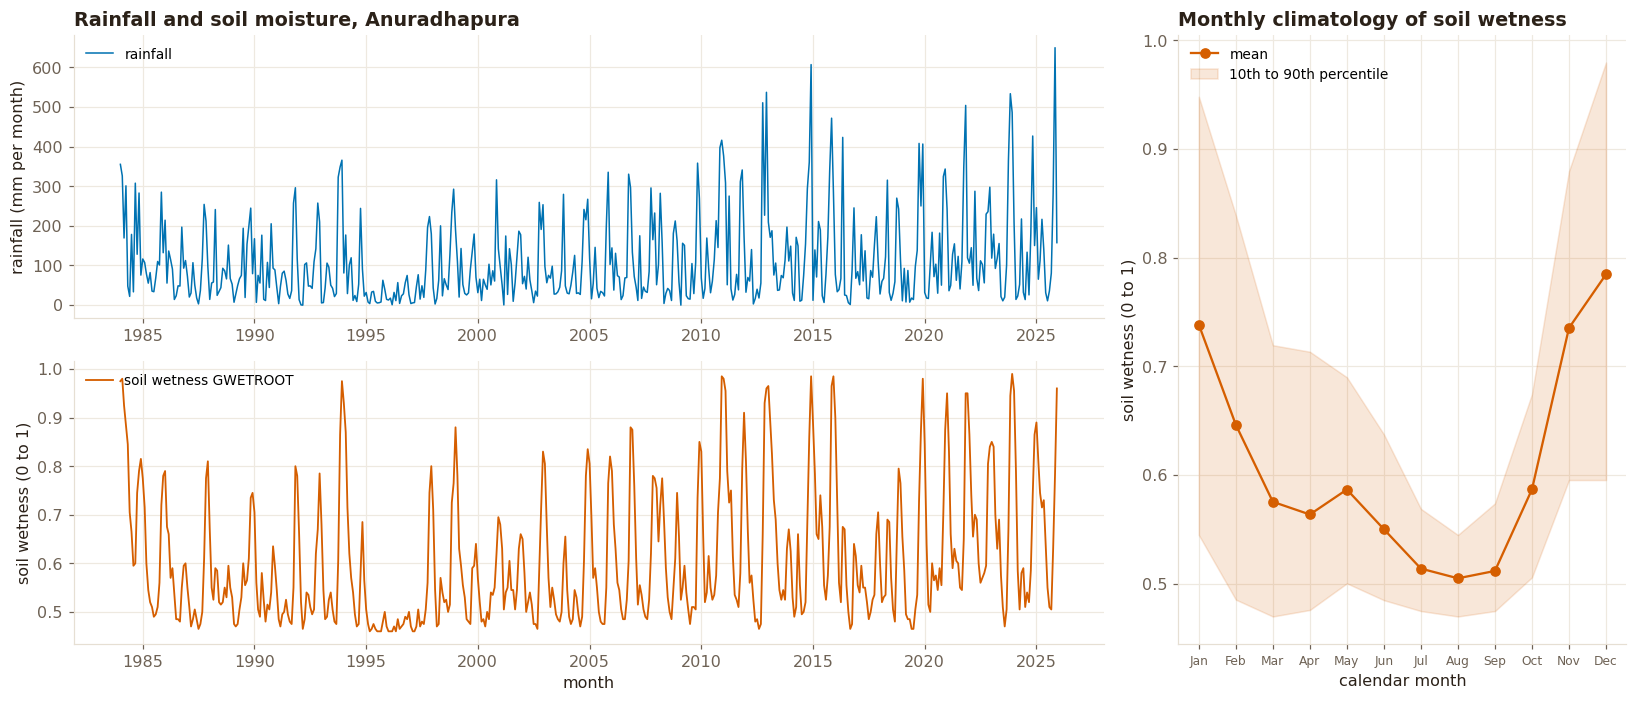

<span style='color:#6E6255'>*Soil wetness rises after each monsoon burst and falls slowly between them; the right panel shows the normal value for each month.*</span>

In [4]:
clim = soil.groupby("Month")["gwetroot"].agg(mean="mean", p10=lambda x: x.quantile(0.1), p90=lambda x: x.quantile(0.9))
view = both[(both["Year"] >= START_YEAR) & (both["Year"] <= END_YEAR)]
fig = plt.figure(figsize=(15, 6.5))
gs = fig.add_gridspec(2, 2, width_ratios=[2.3, 1])
a1 = fig.add_subplot(gs[0, 0]); a2 = fig.add_subplot(gs[1, 0], sharex=a1); a3 = fig.add_subplot(gs[:, 1])
a1.plot(view["date"], view["prcp"], color=theme.INDEX_COLOURS["SPI"], lw=1, label="rainfall")
a1.set_title(f"Rainfall and soil moisture, {DISTRICT}"); a1.set_ylabel("rainfall (mm per month)"); a1.legend(loc="upper left")
a2.plot(view["date"], view["gwetroot"], color=theme.INDEX_COLOURS["SSI"], lw=1.2, label="soil wetness GWETROOT")
a2.set_xlabel("month"); a2.set_ylabel("soil wetness (0 to 1)"); a2.legend(loc="upper left")
a3.plot(clim.index, clim["mean"], color=theme.INDEX_COLOURS["SSI"], marker="o", label="mean")
a3.fill_between(clim.index, clim["p10"], clim["p90"], color=theme.INDEX_COLOURS["SSI"], alpha=0.15, label="10th to 90th percentile")
a3.set_xticks(range(1, 13), [calendar.month_abbr[m] for m in range(1, 13)], fontsize=8)
a3.set_title("Monthly climatology of soil wetness"); a3.set_xlabel("calendar month"); a3.set_ylabel("soil wetness (0 to 1)")
a3.legend()
plt.tight_layout(); plt.show()
nt.caption("Soil wetness rises after each monsoon burst and falls slowly between them; the right panel shows the normal value for each month.")

#### Interpretation

In [5]:
wet_m, dry_m = clim["mean"].idxmax(), clim["mean"].idxmin()
lag_r = {k: both["prcp"].corr(both["gwetroot"].shift(-k)) for k in range(0, 4)}
rain_lag = max(lag_r, key=lag_r.get)
nt.interpret(f"""
Soil in {DISTRICT} is wettest in **{calendar.month_name[wet_m]}** (mean {clim.loc[wet_m, 'mean']:.2f}) and driest in
**{calendar.month_name[dry_m]}** (mean {clim.loc[dry_m, 'mean']:.2f}). Monthly rainfall correlates best with soil wetness
**{rain_lag} month(s) later** (r = {lag_r[rain_lag]:.2f}, against {lag_r[0]:.2f} in the same month): the root zone fills up and
drains slowly, so it keeps a memory of past rain. This is the property that makes SSI useful for paddy: it shows the
water actually available to the roots, not only the rain that fell.
""")


Soil in Anuradhapura is wettest in **December** (mean 0.78) and driest in
**August** (mean 0.51). Monthly rainfall correlates best with soil wetness
**1 month(s) later** (r = 0.83, against 0.63 in the same month): the root zone fills up and
drains slowly, so it keeps a memory of past rain. This is the property that makes SSI useful for paddy: it shows the
water actually available to the roots, not only the rain that fell.


## 2. Distribution fitting per calendar month

For each calendar month the $k$-month mean soil wetness (about 42 values) is fitted with six candidates by
maximum likelihood.

$$\text{Gamma: } f(x)=\frac{x^{\alpha-1}e^{-x/\beta}}{\beta^{\alpha}\Gamma(\alpha)}\qquad
\text{Weibull: } f(x)=\frac{c}{\lambda}\Big(\frac{x}{\lambda}\Big)^{c-1}e^{-(x/\lambda)^c}\qquad
\text{Log-normal: } f(x)=\frac{e^{-(\ln x-\mu)^2/2\sigma^2}}{x\sigma\sqrt{2\pi}}$$

$$\text{Beta on }(0,1):\ f(x)=\frac{x^{a-1}(1-x)^{b-1}}{B(a,b)}\qquad
\text{Normal: } f(x)=\frac{e^{-(x-\mu)^2/2\sigma^2}}{\sigma\sqrt{2\pi}}\qquad
\text{GEV: } f(x)=\frac1\sigma t(x)^{\xi+1}e^{-t(x)}$$

with $t(x)=\big(1+\xi\frac{x-\mu}{\sigma}\big)^{-1/\xi}$. AIC $=2k-2\ln L$, BIC $=k\ln n-2\ln L$, KS $D_n=\sup|F_n-F|$.

In [6]:
FAMILIES = ("gamma", "weibull_min", "lognorm", "beta", "norm", "genextreme")
r = compute_ssi(soil, SCALE)                                   # the project's SSI
mean_k = soil.set_index("date")["gwetroot"].rolling(SCALE, min_periods=SCALE).mean()   # step 1 of compute_ssi
months = pd.Series(mean_k.index.month, index=mean_k.index)
winners = mc.per_month_winners(mean_k, months, FAMILIES, beta_support="unit")
# The family the SSI module itself selected for each calendar month (its own candidate set)
winners["used by the SSI"] = [r.marginals[m].family for m in range(1, 13)]
winners["month"] = winners["month"].map(lambda m: calendar.month_abbr[m])
nt.show(winners.drop(columns="AIC gap Gamma - best"))
print("SSI module candidates:", ", ".join(CANDIDATE_MARGINALS))

,month,best,runner-up,AIC best,KS p best,used by the SSI
0,Jan,Beta,Weibull,-50.1,0.905,beta
1,Feb,Beta,Normal,-44.4,0.581,beta
2,Mar,Log-normal,Gamma,-52.0,0.529,lognorm
3,Apr,GEV,Log-normal,-72.4,0.912,gev
4,May,GEV,Log-normal,-91.2,0.831,gev
5,Jun,GEV,Log-normal,-106.2,0.879,gev
6,Jul,Log-normal,Gamma,-117.3,0.392,lognorm
7,Aug,Log-normal,Gamma,-148.1,0.228,lognorm
8,Sep,GEV,Log-normal,-171.6,0.903,gev
9,Oct,GEV,Log-normal,-158.3,0.782,loglogistic


SSI module candidates: beta, gamma, lognorm, loglogistic, gev, norm


3-month mean soil wetness ending in September: n = 42


,family,parameters,log L,k,AIC,BIC,KS D,KS p
0,GEV,"-0.1026, 0.4942, 0.02342",88.805,3,-171.610,-166.397,0.084,0.903
1,Log-normal,"0.06346, 0, 0.5093",84.551,2,-165.101,-161.626,0.152,0.261
2,Gamma,"243.4, 0, 0.002096",84.106,2,-164.213,-160.737,0.156,0.235
3,Normal,"0.5104, 0.03343",83.139,2,-162.278,-158.802,0.163,0.192
4,Beta,"113.1, 108.5, 0, 1",83.035,2,-162.071,-158.595,0.164,0.188
5,Weibull,"13.3, 0, 0.5271",75.858,2,-147.717,-144.242,0.173,0.145


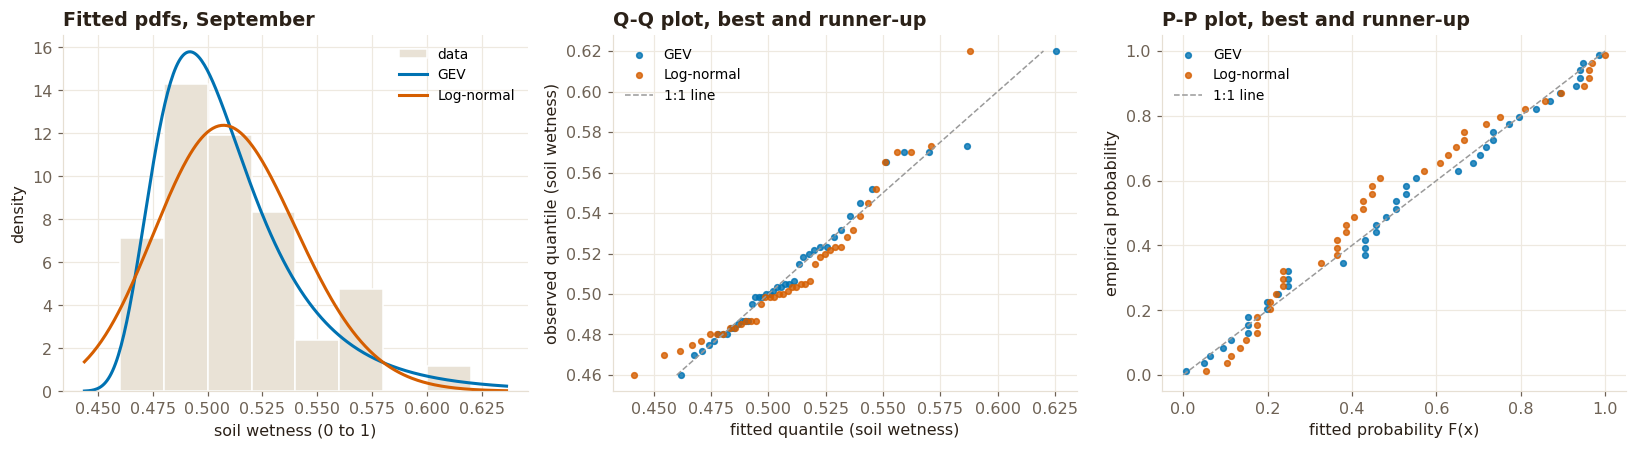

<span style='color:#6E6255'>*Soil wetness is bounded between 0 and 1, so bounded or flexible families (Beta, GEV, Normal) often fit best.*</span>

In [7]:
# Worked month: the calendar month of the driest SSI on record
ssi = r.ssi.dropna()
ex_date = ssi.idxmin()
EX_MONTH = ex_date.month
x_month = mean_k[mean_k.index.month == EX_MONTH].dropna().to_numpy()
fits, frozen = mc.fit_families(x_month, FAMILIES, beta_support="unit")
print(f"{SCALE}-month mean soil wetness ending in {calendar.month_name[EX_MONTH]}: n = {len(x_month)}")
nt.show(fits.drop(columns="scipy"))

best, second = fits.loc[0, "scipy"], fits.loc[1, "scipy"]
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
nt.hist_with_fits(ax[0], x_month, {mc.FAMILY_NAMES[n]: frozen[n] for n in (best, second)},
                  [mc.FAMILY_NAMES[best], mc.FAMILY_NAMES[second]], f"Fitted pdfs, {calendar.month_name[EX_MONTH]}",
                  "soil wetness (0 to 1)")
pair = {mc.FAMILY_NAMES[best]: frozen[best], mc.FAMILY_NAMES[second]: frozen[second]}
nt.qq_plot(ax[1], x_month, pair, "Q-Q plot, best and runner-up", "soil wetness")
nt.pp_plot(ax[2], x_month, pair, "P-P plot, best and runner-up")
plt.tight_layout(); plt.show()
nt.caption("Soil wetness is bounded between 0 and 1, so bounded or flexible families (Beta, GEV, Normal) often fit best.")

#### Interpretation

In [8]:
counts = winners["best"].value_counts()
used = winners["used by the SSI"].value_counts()
nt.interpret(f"""
In this six-family comparison the lowest AIC goes to {', '.join(f'**{k}** ({v} months)' for k, v in counts.items())}.
For {calendar.month_name[EX_MONTH]} the best is **{fits.loc[0, 'family']}** (AIC {fits.loc[0, 'AIC']:.1f}, KS p
{fits.loc[0, 'KS p']:.2f}). The SSI itself follows Sanchez Alcalde and Escorihuela (2025): it picks, for each calendar
month, the lowest-AIC family from {', '.join(CANDIDATE_MARGINALS)}; here that choice is
{', '.join(f'{k} ({v})' for k, v in used.items())}. Choosing per month is reasonable for soil moisture because,
unlike rainfall, there is no single standard family, and the authors showed the choice barely changes the SSI
(checked in step 3 with the robustness correlation).
""")


In this six-family comparison the lowest AIC goes to **GEV** (5 months), **Beta** (3 months), **Log-normal** (3 months), **Gamma** (1 months).
For September the best is **GEV** (AIC -171.6, KS p
0.90). The SSI itself follows Sanchez Alcalde and Escorihuela (2025): it picks, for each calendar
month, the lowest-AIC family from beta, gamma, lognorm, loglogistic, gev, norm; here that choice is
gev (4), beta (3), lognorm (3), loglogistic (1), gamma (1). Choosing per month is reasonable for soil moisture because,
unlike rainfall, there is no single standard family, and the authors showed the choice barely changes the SSI
(checked in step 3 with the robustness correlation).


## 3. SSI calculation and drought classes

The fitted probability of each month's soil wetness is turned into a standard normal score, so SSI uses the
same scale and classes as SPI.

$$\bar\theta^{(k)}_t=\frac1k\sum_{j=0}^{k-1}\theta_{t-j},\qquad \text{SSI}=\Phi^{-1}\big(F_m(\bar\theta^{(k)}_t)\big)$$

A robustness check compares it with the empirical SSI from Gringorten plotting positions,
$p_i = (i-0.44)/(n+0.12)$ for rank $i$ of $n$.

,month,3-month mean wetness,family used,parameters,F(x),SSI = Phi^-1(F),SSI from compute_ssi
0,Sep 1995,0.46,gev,"-0.1026, 0.4942, 0.02342",0.0076,-2.4261,-2.4261


Same as the module: True
Robustness r (parametric vs Gringorten SSI): 0.9865


,class,index range,colour
0,Extremely wet,>= 2,#08306B
1,Very wet,1.5 to 2,#2171B5
2,Moderately wet,1 to 1.5,#6BAED6
3,Near normal,-1 to 1,#EDE8DF
4,Moderately dry,-1.5 to -1,#F4A259
5,Severely dry,-2 to -1.5,#C4561D
6,Extremely dry,<= -2,#7A2E0B


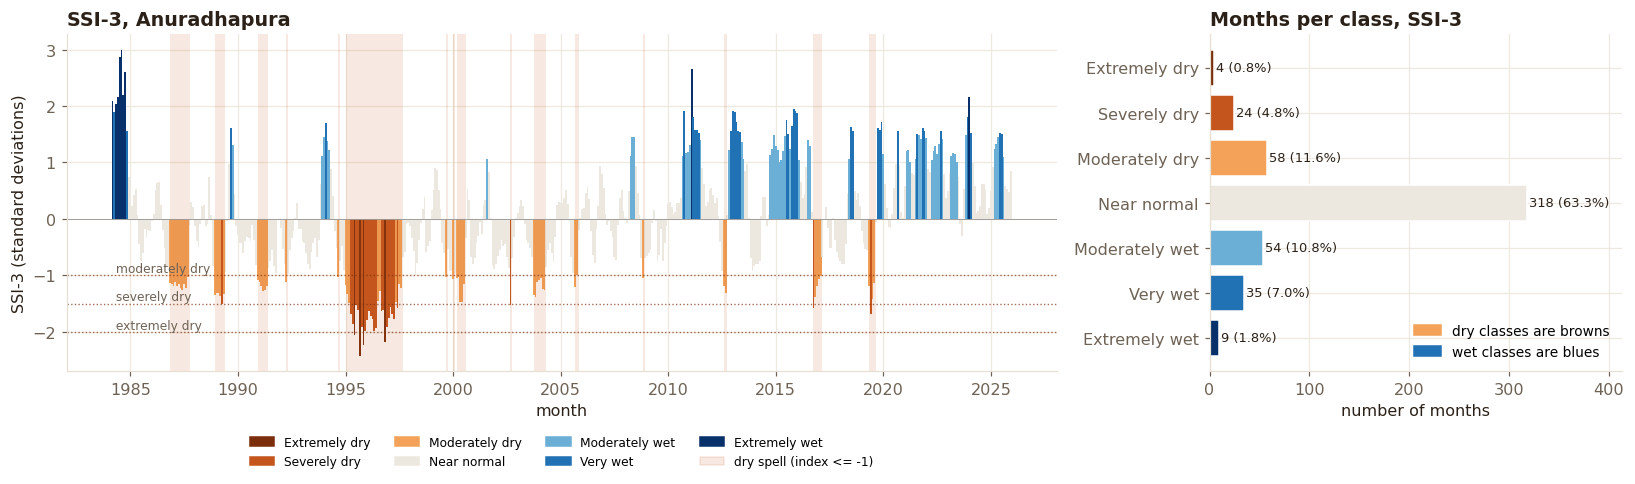

<span style='color:#6E6255'>*Brown bars are drier soil than normal for that month, blue wetter; shaded spans are dry spells (SSI at or below -1).*</span>

In [9]:
fit_m = r.marginals[EX_MONTH]
x = float(mean_k.loc[ex_date])
F = float(fit_m.cdf(np.array([x]))[0])
worked = pd.DataFrame([{"month": f"{ex_date:%b %Y}", f"{SCALE}-month mean wetness": x, "family used": fit_m.family,
                        "parameters": ", ".join(f"{p:.4g}" for p in fit_m.params), "F(x)": F,
                        "SSI = Phi^-1(F)": stats.norm.ppf(np.clip(F, 1e-6, 1 - 1e-6)), "SSI from compute_ssi": ssi.loc[ex_date]}])
nt.show(worked, 4)
print("Same as the module:", np.isclose(stats.norm.ppf(np.clip(F, 1e-6, 1 - 1e-6)), ssi.loc[ex_date]))
print(f"Robustness r (parametric vs Gringorten SSI): {r.robustness_r:.4f}")
nt.show(nt.class_table())

view = ssi[(ssi.index.year >= START_YEAR) & (ssi.index.year <= END_YEAR)]
fig, ax = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw={"width_ratios": [2.4, 1]})
nt.index_bars(ax[0], view.index, view.values, f"SSI-{SCALE}", f"SSI-{SCALE}, {DISTRICT}")
counts_c = nt.class_frequency(ax[1], ssi, f"Months per class, SSI-{SCALE}")
plt.tight_layout(); plt.show()
nt.caption("Brown bars are drier soil than normal for that month, blue wetter; shaded spans are dry spells (SSI at or below -1).")

#### Interpretation

In [10]:
dry = int(counts_c[["Moderately dry", "Severely dry", "Extremely dry"]].sum())
nt.interpret(f"""
The driest soil on record at the {SCALE}-month scale was in **{ex_date:%B %Y}**: mean wetness {x:.3f}, which the
{fit_m.family} fit for {calendar.month_name[EX_MONTH]} places at probability {F:.4f}, so **SSI = {ssi.loc[ex_date]:.2f}**.
{dry} of {int(counts_c.sum())} months ({100 * dry / counts_c.sum():.1f}%) are moderately dry or worse. The robustness
correlation with the empirical SSI is {r.robustness_r:.3f}, so the choice of distribution is not driving the result.
""")


The driest soil on record at the 3-month scale was in **September 1995**: mean wetness 0.460, which the
gev fit for September places at probability 0.0076, so **SSI = -2.43**.
86 of 502 months (17.1%) are moderately dry or worse. The robustness
correlation with the empirical SSI is 0.987, so the choice of distribution is not driving the result.


## 4. Is the SSI standard normal?

The classes only mean the same thing as for SPI if SSI has mean 0, SD 1 and a normal shape.

$$\bar z\approx0,\quad s\approx1,\qquad \text{KS against } N(0,1):\ D_n=\sup_z|F_n(z)-\Phi(z)|$$

,n,mean,SD,skewness,Shapiro-Wilk p,"KS vs N(0,1) D",KS p
0,502,0.004,1.001,0.224,0.001,0.043,0.296


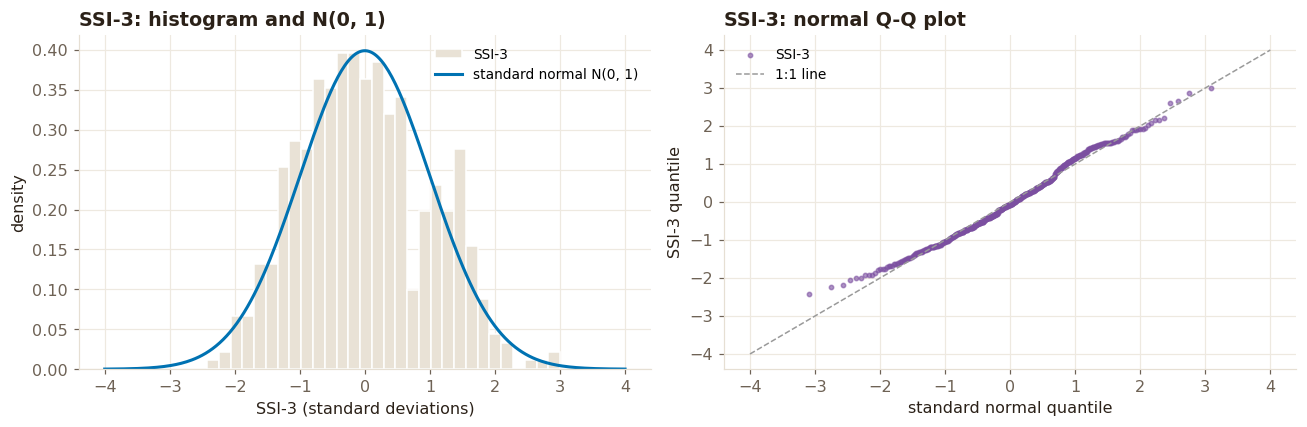

<span style='color:#6E6255'>*The histogram should follow the blue curve and the Q-Q points the dashed line.*</span>

In [11]:
sw = stats.shapiro(ssi)
ks = stats.kstest(ssi, "norm")
nt.show(pd.DataFrame([{"n": len(ssi), "mean": ssi.mean(), "SD": ssi.std(), "skewness": stats.skew(ssi),
                       "Shapiro-Wilk p": sw.pvalue, "KS vs N(0,1) D": ks.statistic, "KS p": ks.pvalue}]))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
nt.normal_check(ax, ssi, f"SSI-{SCALE}")
plt.tight_layout(); plt.show()
nt.caption("The histogram should follow the blue curve and the Q-Q points the dashed line.")

#### Interpretation

In [12]:
nt.interpret(f"""
SSI-{SCALE} has mean **{ssi.mean():+.3f}** and SD **{ssi.std():.3f}**. The KS test against N(0, 1) gives p = {ks.pvalue:.3f}
({'not rejected' if ks.pvalue >= 0.05 else 'rejected'}) and Shapiro-Wilk p = {sw.pvalue:.3g}. With {len(ssi)} overlapping
monthly values these tests are strict; the Q-Q plot is the better guide, and it shows the dry tail close to the
line, so an SSI of -1.5 is about as rare as an SPI of -1.5.
""")


SSI-3 has mean **+0.004** and SD **1.001**. The KS test against N(0, 1) gives p = 0.296
(not rejected) and Shapiro-Wilk p = 0.00121. With 502 overlapping
monthly values these tests are strict; the Q-Q plot is the better guide, and it shows the dry tail close to the
line, so an SSI of -1.5 is about as rare as an SPI of -1.5.


## 5. Drought events, marginals, copula and return periods

The same steps as for SPI (notebook 01): runs below 0 give events with duration $D$ and severity $S$;
$D\sim$ Exponential and $S\sim$ Gamma are joined by the Gumbel, Clayton or Frank copula with the lowest AIC.

$$D=t_e-t_s+1,\quad S=\sum_{t_s}^{t_e}|\text{SSI}_t|,\qquad F(d,s)=C\big(F_D(d),F_S(s)\big)$$

$$T_{AND}=\frac{E(L)}{12\,[1-F_D-F_S+C]},\qquad T_{OR}=\frac{E(L)}{12\,[1-C]}$$

In [13]:
# Same call as the dashboard's SSI events tab
series = pd.DataFrame({"Year": ssi.index.year, "Month": ssi.index.month, "value": ssi.values})
model, events = index_data.events_and_model(series, DISTRICT, SCALE)
EV_DISTRICT = DISTRICT
if model is None:
    # Too few events for a duration-severity copula (the fit needs at least 10): show a district that has enough
    print(f"{DISTRICT} has only {len(events)} SSI-{SCALE} events, too few for the copula (at least 10). This section uses {common.VALIDATION_DISTRICTS[0]}.")
    EV_DISTRICT = common.VALIDATION_DISTRICTS[0]
    other = compute_ssi(common.read_soil(EV_DISTRICT), SCALE).ssi
    series = pd.DataFrame({"Year": other.index.year, "Month": other.index.month, "value": other.values})
    model, events = index_data.events_and_model(series, EV_DISTRICT, SCALE)
print(f"{EV_DISTRICT}: {model.n_events} SSI events, E(L) = {model.EL_months:.2f} months, Kendall tau = {model.kendall_tau:.3f}")
nt.show(events.sort_values("Severity", ascending=False).head(8))

MARG = ("expon", "gamma", "weibull_min", "lognorm")
fit_d, frozen_d = mc.fit_families(events["Duration"].astype(float), MARG)
fit_s, frozen_s = mc.fit_families(events["Severity"].astype(float), MARG)
print("Duration D"); nt.show(fit_d.drop(columns="scipy"))
print("Severity S"); nt.show(fit_s.drop(columns="scipy"))
cop = mc.ds_copula_table(model, events, n_boot=N_BOOT)
print("Copulas"); nt.show(cop, 4)

Anuradhapura: 29 SSI events, E(L) = 17.31 months, Kendall tau = 0.825


,StartYear,StartMonth,EndYear,EndMonth,Duration,Severity
8,1994,7,1998,7,49,63.001
5,1989,12,1991,11,24,15.675
1,1986,7,1987,10,16,15.326
13,2003,5,2004,10,18,14.116
10,1999,7,2000,8,14,12.991
4,1988,11,1989,7,9,10.019
12,2001,11,2002,11,13,9.099
26,2019,1,2019,9,9,7.222


Duration D


,family,parameters,log L,k,AIC,BIC,KS D,KS p
0,Log-normal,"0.8791, 0, 6.148",-90.083,2,184.165,186.900,0.145,0.530
1,Gamma,"1.47, 0, 6.099",-91.433,2,186.867,189.602,0.147,0.508
2,Exponential,"0, 8.966",-92.608,1,187.216,188.584,0.143,0.545
3,Weibull,"1.157, 0, 9.505",-92.051,2,188.101,190.836,0.150,0.488


Severity S


,family,parameters,log L,k,AIC,BIC,KS D,KS p
0,Weibull,"0.7648, 0, 5.895",-83.364,2,170.728,173.463,0.086,0.969
1,Gamma,"0.6813, 0, 10.33",-83.949,2,171.899,174.633,0.108,0.855
2,Log-normal,"1.526, 0, 2.89",-84.180,2,172.361,175.096,0.141,0.561
3,Exponential,"0, 7.04",-85.597,1,173.195,174.562,0.161,0.395


Copulas


,family,theta,log L,AIC,BIC,lambda_U,lambda_L,CvM p,selected
0,Gumbel,4.3911,29.2280,-56.4559,-55.0886,0.829,0.0000,0.0050,
1,Clayton,3.9939,19.5574,-37.1148,-35.7475,0.000,0.8407,0.0050,
2,Frank,17.7266,30.2546,-58.5092,-57.1419,0.000,0.0000,0.0030,yes
3,Gaussian (check),0.9519,31.9054,-61.8107,-60.4435,0.000,0.0000,0.0115,


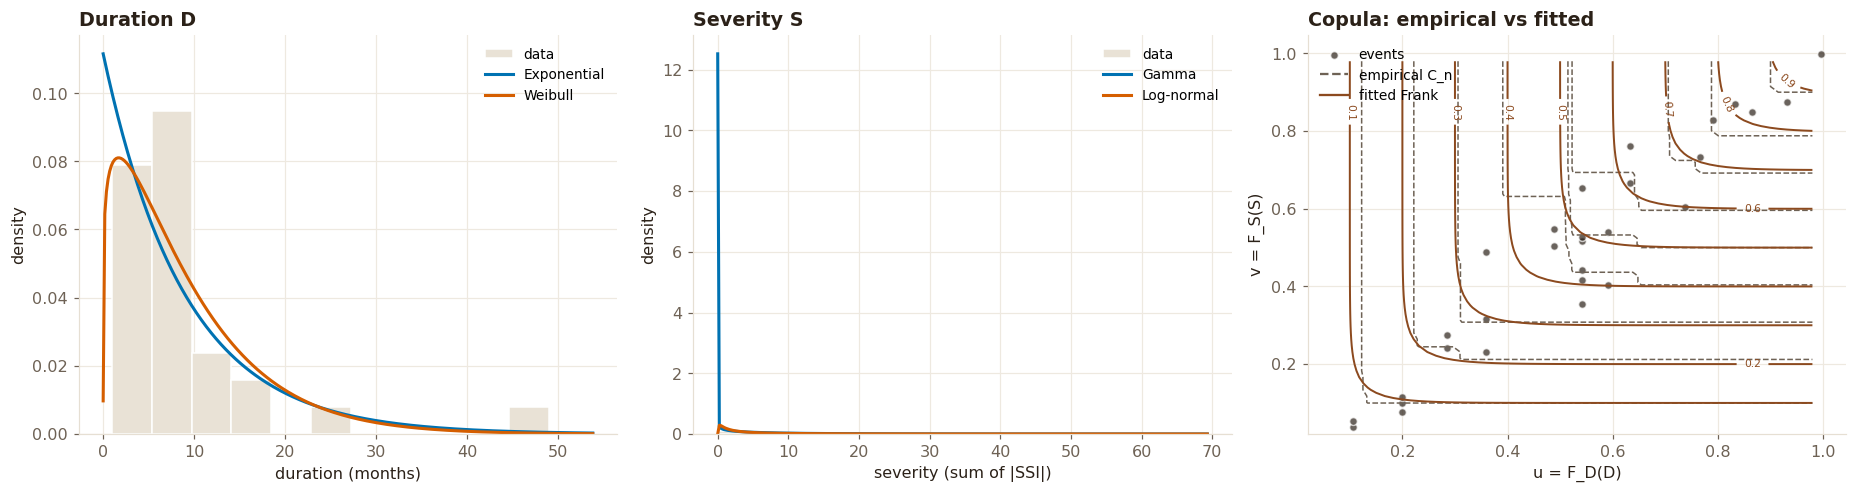

<span style='color:#6E6255'>*Left and middle: marginal fits. Right: the selected copula (solid) against the empirical copula (dashed).*</span>

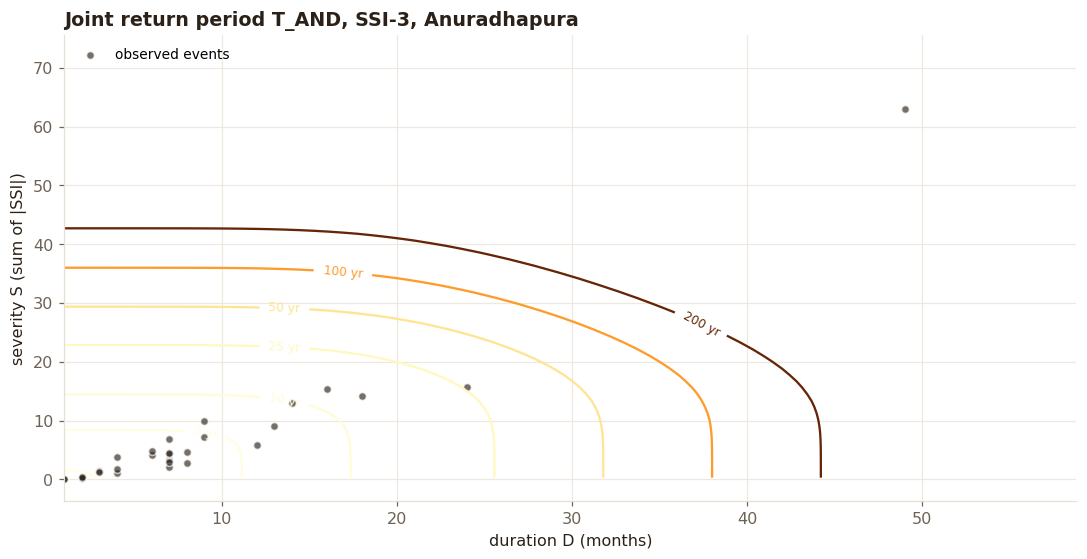

<span style='color:#6E6255'>*Each curve joins soil droughts that are equally rare.*</span>

,Return period (years),Drought length (months),Drought severity score,"T_AND(d,s) years","T_OR(d,s) years"
0,2,2.9,1.49,2.1,1.9
1,5,11.1,8.44,5.8,4.4
2,10,17.4,14.47,13.4,8.0
3,20,23.6,20.79,34.8,14.0
4,50,31.8,29.38,146.4,30.1
5,100,38.0,36.01,489.4,55.7


In [14]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
nt.hist_with_fits(ax[0], events["Duration"], {"Exponential": frozen_d["expon"], "Weibull": frozen_d["weibull_min"]},
                  ["Exponential", "Weibull"], "Duration D", "duration (months)")
nt.hist_with_fits(ax[1], events["Severity"], {"Gamma": frozen_s["gamma"], "Log-normal": frozen_s["lognorm"]},
                  ["Gamma", "Log-normal"], "Severity S", "severity (sum of |SSI|)")
g = np.linspace(0.02, 0.98, 60); GU, GV = np.meshgrid(g, g)
fitted = np.asarray(_copula_cdf(model.best_family, GU.ravel(), GV.ravel(), model.best_theta)).reshape(GU.shape)
emp = mc.empirical_copula_grid(events["Duration"].values, events["Severity"].values, g)
ax[2].contour(g, g, emp, levels=np.arange(0.1, 1, 0.1), colors=theme.MUTED, linestyles="--", linewidths=1)
cs = ax[2].contour(GU, GV, fitted, levels=np.arange(0.1, 1, 0.1), colors=theme.ACCENT, linewidths=1.3)
ax[2].clabel(cs, fontsize=7)
ax[2].scatter(model.marginals.F_D(events["Duration"].values), model.marginals.F_S(events["Severity"].values),
              s=26, color=theme.INK, alpha=0.7, edgecolor="white", label="events")
ax[2].plot([], [], color=theme.MUTED, ls="--", label="empirical C_n"); ax[2].plot([], [], color=theme.ACCENT, label=f"fitted {model.best_family}")
ax[2].set_title("Copula: empirical vs fitted"); ax[2].set_xlabel("u = F_D(D)"); ax[2].set_ylabel("v = F_S(S)"); ax[2].legend(loc="upper left")
plt.tight_layout(); plt.show()
nt.caption("Left and middle: marginal fits. Right: the selected copula (solid) against the empirical copula (dashed).")

dg = np.linspace(1, max(events["Duration"].max() * 1.2, 12), 70); sg = np.linspace(0.3, max(events["Severity"].max() * 1.2, 8), 70)
TA = np.array([[T_and(model, d, s) for d in dg] for s in sg])
fig, ax = plt.subplots(figsize=(10, 5.2))
cs = ax.contour(dg, sg, TA, levels=[2, 5, 10, 25, 50, 100, 200], cmap="YlOrBr", linewidths=1.5)
ax.clabel(cs, fmt="%d yr", fontsize=8)
ax.scatter(events["Duration"], events["Severity"], s=26, color=theme.INK, alpha=0.65, edgecolor="white", label="observed events")
ax.set_title(f"Joint return period T_AND, SSI-{SCALE}, {EV_DISTRICT}"); ax.set_xlabel("duration D (months)")
ax.set_ylabel("severity S (sum of |SSI|)"); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()
nt.caption("Each curve joins soil droughts that are equally rare.")
rp = return_period_table(model)
nt.show(rp)

#### Interpretation

In [15]:
sel = cop[cop["selected"] == "yes"].iloc[0]
w = events.loc[events["Severity"].idxmax()]
nt.interpret(f"""
{"" if EV_DISTRICT == DISTRICT else DISTRICT + " has too few events for a copula, so these figures are for " + EV_DISTRICT + ". "}SSI-{SCALE} gives **{model.n_events} soil-moisture drought events** (mean length {model.marginals.mean_D:.1f} months), the
worst from {int(w['StartMonth'])}/{int(w['StartYear'])} to {int(w['EndMonth'])}/{int(w['EndYear'])} ({int(w['Duration'])} months,
severity {w['Severity']:.1f}). The selected copula is **{sel['family']}** (theta {sel['theta']:.2f}, AIC {sel['AIC']:.1f},
bootstrap p {sel['CvM p']:.3f}). A drought at least 6 months long and at least 6 severe returns every
**{T_and(model, 6, 6):.1f} years** (T_AND). Compared with rainfall, soil droughts are fewer but longer, because the root
zone smooths out short gaps in the rain.
""")


SSI-3 gives **29 soil-moisture drought events** (mean length 9.0 months), the
worst from 7/1994 to 7/1998 (49 months,
severity 63.0). The selected copula is **Frank** (theta 17.73, AIC -58.5,
bootstrap p 0.003). A drought at least 6 months long and at least 6 severe returns every
**3.8 years** (T_AND). Compared with rainfall, soil droughts are fewer but longer, because the root
zone smooths out short gaps in the rain.


## 6. Validation of the SSI

Three checks: (a) how closely SSI follows SPI and at which delay, (b) whether the two flag the same dry months,
(c) whether SSI finds the test droughts without flagging too many other years. SSI is scored on the same test droughts and by the
same rule as MSDI and SPI (`threshold_skill.py`): impact, situation report, DMC report and news impact rows only.

$$r(k)=\operatorname{corr}\big(\text{SPI}_t,\ \text{SSI}_{t+k}\big),\qquad
\text{HR}=\frac{\text{test droughts with a flagged year}}{\text{test droughts}},\qquad
\text{FAR}=\frac{\text{flagged years with no drought evidence}}{\text{years with no drought evidence}}$$

A year is flagged when it has at least 3 months at or below -1 (`compare_indices.py`, same as the dashboard).

,scale,Pearson r,Spearman rho,best lag (months),r at best lag
0,1,0.619,0.607,1,0.658
1,3,0.800,0.789,1,0.879
2,6,0.898,0.893,1,0.938


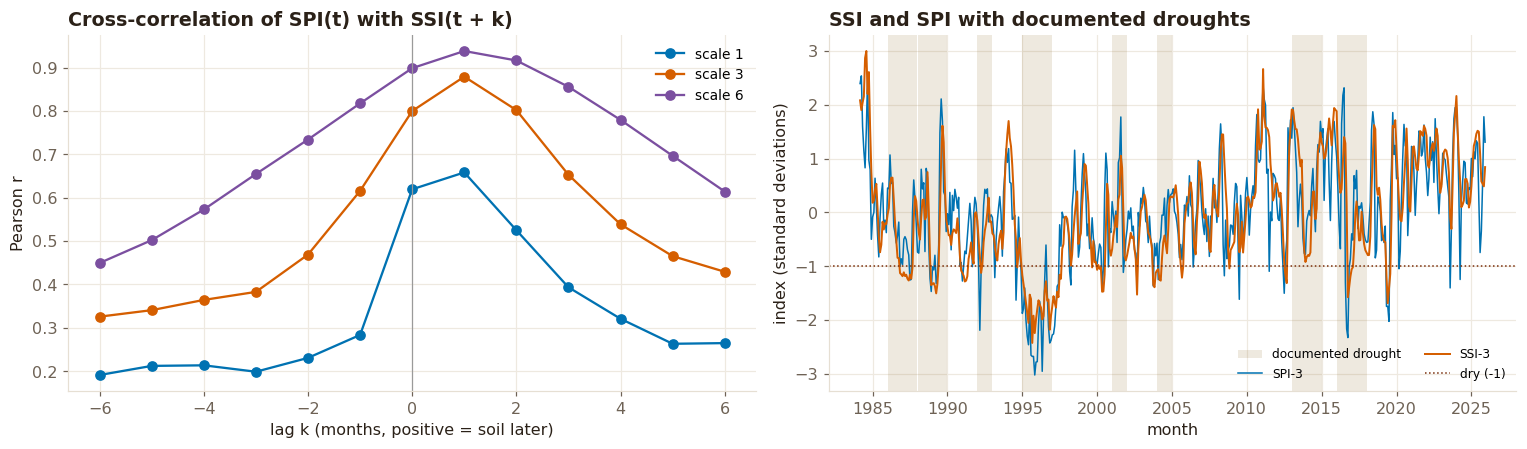

<span style='color:#6E6255'>*Left: the peak of each curve is the delay at which soil best follows rain. Right: shaded bands are documented droughts.*</span>

,SSI-3 dry,SSI-3 not dry
SPI-3 dry,49,22
SPI-3 not dry,37,394


,index,test droughts,hit rate,false-alarm rate,droughts detected,false-alarm years,skill (HR - FAR)
0,SPI,8,0.375,0.08,"1995-96, 2016-17, 2019","1997, 2000",0.295
1,SSI,8,0.625,0.16,"1986-87, 1995-96, 2004, 2016-17, 2019","1991, 1997, 2000, 2003",0.465


SSI-3 per province, on the shared test droughts


,province,test droughts,hit rate,false alarm rate,skill,warning
11,North Central,8,0.56,0.16,0.40,
53,North Western,5,0.44,0.27,0.17,
17,Uva,4,0.14,0.30,-0.16,"very few test droughts, treat as indicative only"
29,Southern,4,0.40,0.35,0.05,"very few test droughts, treat as indicative only"
5,Eastern,3,0.50,0.26,0.24,"very few test droughts, treat as indicative only"
35,Northern,3,0.44,0.31,0.13,"very few test droughts, treat as indicative only"
41,Central,1,1.00,0.28,0.72,"very few test droughts, treat as indicative only"


In [16]:
corr_rows, frames = [], {}
for k in common.SCALES:
    df = CI.load_indices(DISTRICT, k)                         # SPI, SSI, MSDI, as in comparison_outputs/
    frames[k] = df
    ps = CI.pair_stats(df, "SPI", "SSI")
    corr_rows.append({"scale": k, "Pearson r": ps["pearson SPI-SSI"], "Spearman rho": ps["spearman SPI-SSI"],
                      "best lag (months)": ps["best lag SPI-SSI (months)"], "r at best lag": ps["best lag r SPI-SSI"]})
corr = pd.DataFrame(corr_rows)
nt.show(corr)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
for k, c in zip(common.SCALES, [theme.INDEX_COLOURS["SPI"], theme.INDEX_COLOURS["SSI"], theme.INDEX_COLOURS["MSDI"]]):
    cc = mc.cross_correlation(frames[k]["SPI"], frames[k]["SSI"])
    ax[0].plot(cc["lag (months)"], cc["r"], marker="o", color=c, label=f"scale {k}")
ax[0].axvline(0, color="#9A9A9A", lw=0.8)
ax[0].set_title("Cross-correlation of SPI(t) with SSI(t + k)"); ax[0].set_xlabel("lag k (months, positive = soil later)")
ax[0].set_ylabel("Pearson r"); ax[0].legend()
df = frames[SCALE]
dfp = df.reset_index(); dfp["Date"] = pd.to_datetime(dfp[["Year", "Month"]].assign(day=1))
dfp = dfp[(dfp["Year"] >= START_YEAR) & (dfp["Year"] <= END_YEAR)]
nt.shade_documented(ax[1])
ax[1].plot(dfp["Date"], dfp["SPI"], color=theme.INDEX_COLOURS["SPI"], lw=1, label=f"SPI-{SCALE}")
ax[1].plot(dfp["Date"], dfp["SSI"], color=theme.INDEX_COLOURS["SSI"], lw=1.3, label=f"SSI-{SCALE}")
ax[1].axhline(-1, color=theme.DRY_LINE, ls=":", lw=1, label="dry (-1)")
ax[1].set_title("SSI and SPI with documented droughts"); ax[1].set_xlabel("month"); ax[1].set_ylabel("index (standard deviations)")
ax[1].legend(ncol=2, fontsize=8)
plt.tight_layout(); plt.show()
nt.caption("Left: the peak of each curve is the delay at which soil best follows rain. Right: shaded bands are documented droughts.")

overlap = mc.dry_overlap(df["SPI"], df["SSI"], f"SPI-{SCALE}", f"SSI-{SCALE}")
nt.show(overlap)
# The shared test droughts: this district's if it has any, otherwise Anuradhapura's
VAL = DISTRICT if len(TH.current().test_for(DISTRICT)) else common.VALIDATION_DISTRICTS[0]
vdf = CI.load_indices(VAL, SCALE)
val = pd.DataFrame([{"index": n, **{k.replace(f" {n}", ""): v for k, v in CI.validation_stats(vdf, n, district=VAL).items()}}
                    for n in ("SPI", "SSI")])
val["skill (HR - FAR)"] = val["hit rate"] - val["false-alarm rate"]
val = val[["index", "test droughts"] + [c for c in val.columns if c not in ("index", "test droughts")]]
nt.show(val)

shared = TS.compute()
ssi_prov = shared.by_province[shared.by_province["index"] == "SSI-3"]
keep = ["province", "separate droughts", "hit rate", "false alarm rate", "skill", "warning"]
print("SSI-3 per province, on the shared test droughts")
nt.show(ssi_prov[keep].rename(columns={"separate droughts": "test droughts"}).dropna(subset=["skill"]).sort_values("test droughts", ascending=False), 2)

#### Interpretation

In [17]:
c = corr.set_index("scale")
s_row, p_row = val.set_index("index").loc["SSI"], val.set_index("index").loc["SPI"]
nt.interpret(f"""
SSI follows SPI closely: r = {c.loc[1, 'Pearson r']:.2f}, {c.loc[3, 'Pearson r']:.2f} and {c.loc[6, 'Pearson r']:.2f} at 1, 3 and 6
months, and the best match comes **{int(c.loc[SCALE, 'best lag (months)'])} month(s) later** at the {SCALE}-month scale
(r = {c.loc[SCALE, 'r at best lag']:.2f}). Of the months SPI-{SCALE} flags as dry, {overlap.iloc[0, 0]} are also dry in the soil
and {overlap.iloc[0, 1]} are not; the soil is dry on its own in {overlap.iloc[1, 0]} months, often the months right after a
rainfall drought ends. {'' if DISTRICT == VAL else DISTRICT + ' has no test droughts, so the next figures are for ' + VAL + '. '}On the {len(TH.current().test_for(VAL))} test droughts of {VAL},
SSI-{SCALE} has hit rate **{s_row['hit rate']:.2f}** and false-alarm rate **{s_row['false-alarm rate']:.2f}**
(SPI: {p_row['hit rate']:.2f} and {p_row['false-alarm rate']:.2f}). Droughts found by SSI: {s_row['droughts detected']}. Over all tested districts, on {int(shared.national.set_index('index').loc['SSI-3', 'separate droughts'])} test droughts, SSI-3 has skill **{shared.national.set_index('index').loc['SSI-3', 'skill']:+.2f}**.
Provinces marked "{TS.FEW_WARNING}" move a lot on one drought. Notebook 03 shows SPI, SSI and MSDI side by side.
""")


SSI follows SPI closely: r = 0.62, 0.80 and 0.90 at 1, 3 and 6
months, and the best match comes **1 month(s) later** at the 3-month scale
(r = 0.88). Of the months SPI-3 flags as dry, 49 are also dry in the soil
and 22 are not; the soil is dry on its own in 37 months, often the months right after a
rainfall drought ends. On the 8 test droughts of Anuradhapura,
SSI-3 has hit rate **0.62** and false-alarm rate **0.16**
(SPI: 0.38 and 0.08). Droughts found by SSI: 1986-87, 1995-96, 2004, 2016-17, 2019. Over all tested districts, on 11 test droughts, SSI-3 has skill **+0.17**.
Provinces marked "very few test droughts, treat as indicative only" move a lot on one drought. Notebook 03 shows SPI, SSI and MSDI side by side.


## 7. All 25 districts

The SSI for every district from the dashboard's index tables (`index_data.load_tables`), with the same
statistics as `comparison_outputs/index_comparison_summary.csv`.

,district,pearson SPI-SSI,best lag SPI-SSI (months),% dry months SSI,events SSI,mean duration SSI,longest duration SSI,events SPI,mean duration SPI
1,Ampara,0.84,1,15.34,25,10.96,49,50,5.34
4,Anuradhapura,0.80,1,17.13,29,8.97,49,58,4.34
7,Badulla,0.86,1,14.14,20,13.15,51,37,7.19
10,Batticaloa,0.80,1,16.14,33,8.09,38,57,4.51
13,Colombo,0.82,1,19.92,17,15.00,50,49,5.16
16,Galle,0.83,1,21.71,6,44.00,176,38,6.79
19,Gampaha,0.82,1,19.92,17,15.00,50,49,5.16
22,Hambantota,0.85,1,16.33,18,14.11,50,38,6.74
25,Jaffna,0.79,1,17.73,36,7.25,49,59,4.32
28,Kalutara,0.86,1,20.92,13,20.08,92,39,6.56


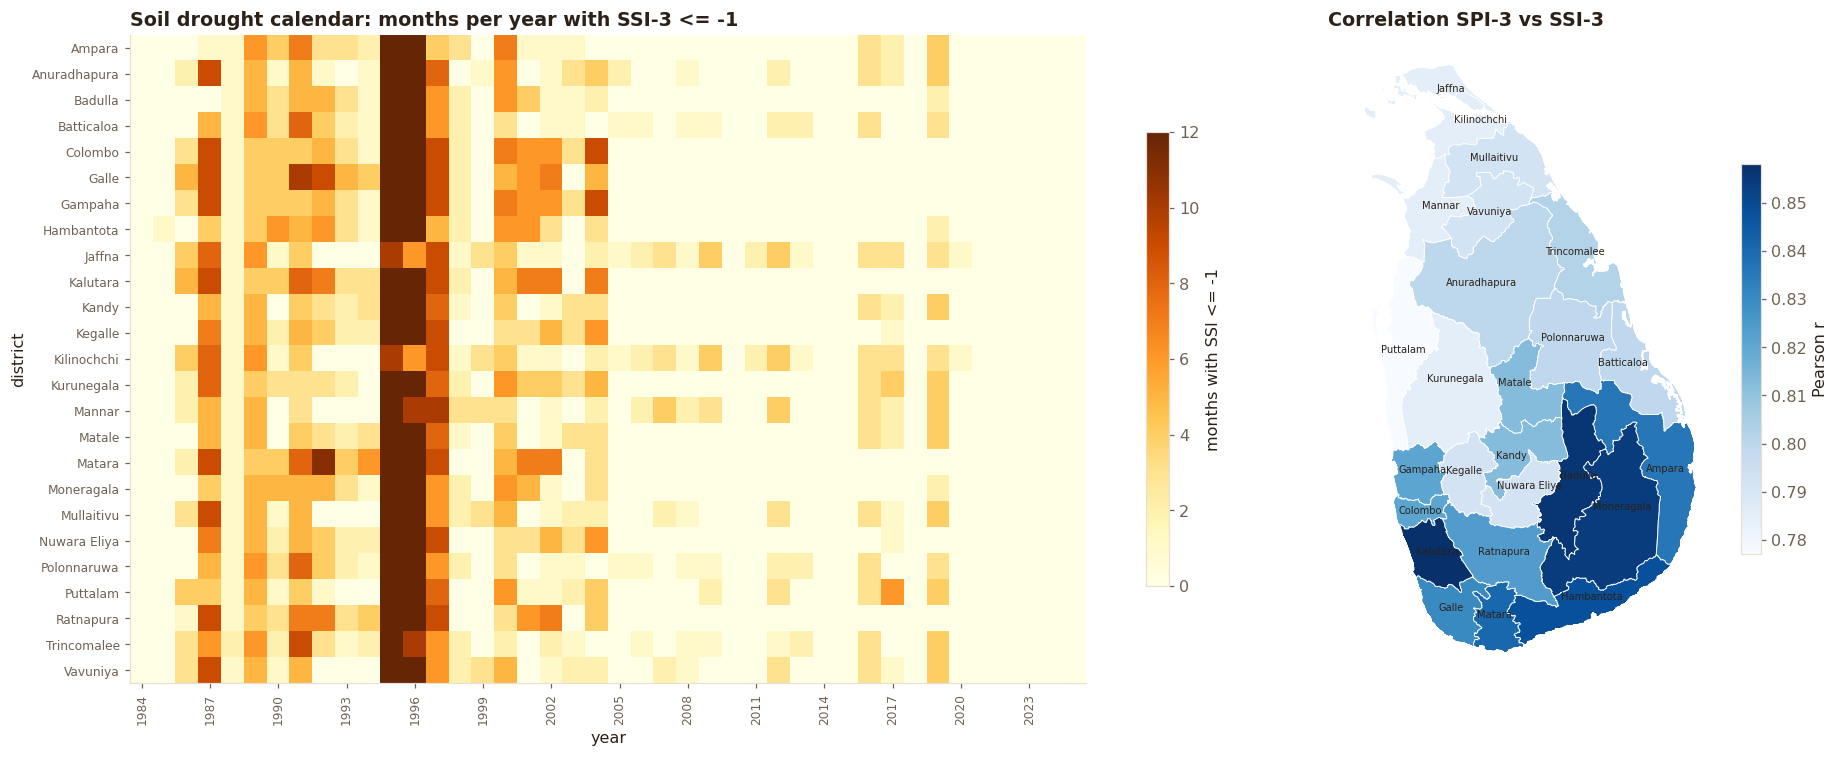

<span style='color:#6E6255'>*Dark vertical stripes on the left are island-wide soil droughts; the map shows where soil follows rain most closely.*</span>

In [18]:
tables = index_data.load_tables()["tables"]
summ = pd.read_csv("comparison_outputs/index_comparison_summary.csv")
summ = summ[summ["scale"] == SCALE][["district", "pearson SPI-SSI", "best lag SPI-SSI (months)", "% dry months SSI",
                                      "events SSI", "mean duration SSI", "longest duration SSI", "events SPI",
                                      "mean duration SPI"]]
nt.show(summ, 2)

t = tables[("SSI", SCALE)]
heat = (t.assign(dry=t["value"] <= -1).groupby(["District", "Year"])["dry"].sum().unstack("Year"))
fig, ax = plt.subplots(1, 2, figsize=(17, 7), gridspec_kw={"width_ratios": [2.2, 1]})
im = ax[0].imshow(heat.values, aspect="auto", cmap="YlOrBr", vmin=0, vmax=12)
ax[0].set_yticks(range(len(heat)), heat.index, fontsize=8)
ax[0].set_xticks(range(0, heat.shape[1], 3), heat.columns[::3], rotation=90, fontsize=8)
ax[0].grid(False)
fig.colorbar(im, ax=ax[0], shrink=0.7, label="months with SSI <= -1")
ax[0].set_title(f"Soil drought calendar: months per year with SSI-{SCALE} <= -1"); ax[0].set_xlabel("year"); ax[0].set_ylabel("district")
nt.district_map(ax[1], summ.set_index("district")["pearson SPI-SSI"], f"Correlation SPI-{SCALE} vs SSI-{SCALE}",
                cmap="Blues", label="Pearson r")
plt.tight_layout(); plt.show()
nt.caption("Dark vertical stripes on the left are island-wide soil droughts; the map shows where soil follows rain most closely.")

#### Interpretation

In [19]:
years = heat.sum().sort_values(ascending=False)
lowr = summ.nsmallest(3, "pearson SPI-SSI")
nt.interpret(f"""
The island-wide soil-drought years stand out as dark columns: the worst are {', '.join(f'{y} ({int(v)} district-months)' for y, v in years.head(4).items())}.
Across districts SSI has {summ['events SSI'].min():.0f} to {summ['events SSI'].max():.0f} events against {summ['events SPI'].min():.0f} to
{summ['events SPI'].max():.0f} for SPI, and they last longer on average ({summ['mean duration SSI'].mean():.1f} vs
{summ['mean duration SPI'].mean():.1f} months). Soil follows rain least closely in {', '.join(f"{r['district']} (r {r['pearson SPI-SSI']:.2f})" for _, r in lowr.iterrows())}.
""" + "".join(f"""

**Data check: {r['district']}** has only {int(r['events SSI'])} SSI events and the longest lasts {int(r['longest duration SSI'])}
months ({int(r['longest duration SSI']) / 12:.0f} years). A soil drought that long is not plausible for a wet-zone district; the
GWETROOT series of that grid cell probably has a long-term drift, so its SSI events should not be used without checking
the raw soil data.""" for _, r in summ[summ["longest duration SSI"] > 120].iterrows()))


The island-wide soil-drought years stand out as dark columns: the worst are 1995 (296 district-months), 1996 (284 district-months), 1997 (191 district-months), 1987 (163 district-months).
Across districts SSI has 6 to 38 events against 36 to
64 for SPI, and they last longer on average (14.1 vs
5.3 months). Soil follows rain least closely in Puttalam (r 0.78), Jaffna (r 0.79), Kilinochchi (r 0.79).


**Data check: Galle** has only 6 SSI events and the longest lasts 176
months (15 years). A soil drought that long is not plausible for a wet-zone district; the
GWETROOT series of that grid cell probably has a long-term drift, so its SSI events should not be used without checking
the raw soil data.

**Data check: Matara** has only 6 SSI events and the longest lasts 156
months (13 years). A soil drought that long is not plausible for a wet-zone district; the
GWETROOT series of that grid cell probably has a long-term drift, so its SSI events should not be used without checking
the raw soil data.

## 8. How soil moisture lags rainfall, and what it means for paddy

The lag found above is the time the root zone takes to respond to a change in rain. It decides when a rainfall
deficit turns into crop water stress.

$$k^* = \arg\max_k\ \operatorname{corr}\big(\text{SPI}_t,\ \text{SSI}_{t+k}\big)$$

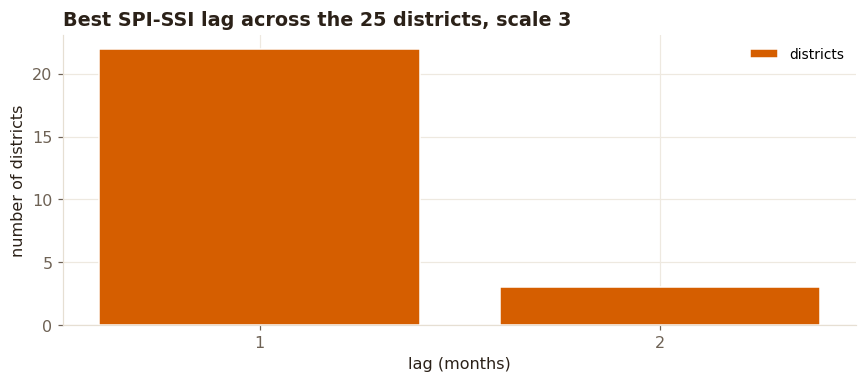

<span style='color:#6E6255'>*Most districts respond with the same short delay.*</span>

In [20]:
lags = summ["best lag SPI-SSI (months)"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(lags.index.astype(str), lags.values, color=theme.INDEX_COLOURS["SSI"], edgecolor="white", label="districts")
ax.set_title(f"Best SPI-SSI lag across the 25 districts, scale {SCALE}"); ax.set_xlabel("lag (months)")
ax.set_ylabel("number of districts"); ax.legend()
plt.tight_layout(); plt.show()
nt.caption("Most districts respond with the same short delay.")

#### Interpretation

In [21]:
mode_lag = int(lags.idxmax())
nt.interpret(f"""
In {lags.max()} of 25 districts soil moisture follows rainfall best after **{mode_lag} month(s)** at the {SCALE}-month scale;
{DISTRICT} has a lag of {int(c.loc[SCALE, 'best lag (months)'])}. For paddy this delay is useful warning time: when SPI drops
below -1 at the start of a Maha or Yala season, the root zone typically dries {mode_lag} month(s) later, during
tillering and panicle initiation, the stages most sensitive to water stress. Equally, soil keeps the crop going for a
while after the rain stops, and can stay dry after the rain returns, which is why SSI droughts last longer than SPI
droughts ({summ['mean duration SSI'].mean():.1f} vs {summ['mean duration SPI'].mean():.1f} months on average).
""")


In 22 of 25 districts soil moisture follows rainfall best after **1 month(s)** at the 3-month scale;
Anuradhapura has a lag of 1. For paddy this delay is useful warning time: when SPI drops
below -1 at the start of a Maha or Yala season, the root zone typically dries 1 month(s) later, during
tillering and panicle initiation, the stages most sensitive to water stress. Equally, soil keeps the crop going for a
while after the rain stops, and can stay dry after the rain returns, which is why SSI droughts last longer than SPI
droughts (14.1 vs 5.3 months on average).


## 9. Summary of findings

In [22]:
nt.interpret(f"""
1. Soil wetness in {DISTRICT} peaks in {calendar.month_name[wet_m]} and is lowest in {calendar.month_name[dry_m]}, and lags rainfall by about {rain_lag} month(s).
2. The SSI uses the lowest-AIC family per calendar month; the robustness correlation with the empirical SSI is {r.robustness_r:.3f}.
3. SSI-{SCALE} has mean {ssi.mean():+.2f} and SD {ssi.std():.2f}, so the McKee classes apply.
4. The driest soil on record was in {ex_date:%B %Y} (SSI {ssi.loc[ex_date]:.2f}).
5. SSI-{SCALE} gives {model.n_events} drought events joined by the {model.best_family} copula; a 6-month, severity-6 soil drought returns every {T_and(model, 6, 6):.1f} years.
6. SSI and SPI correlate at r = {c.loc[SCALE, 'Pearson r']:.2f} at the {SCALE}-month scale, best at a lag of {int(c.loc[SCALE, 'best lag (months)'])} month(s).
7. Against the test droughts SSI-{SCALE} has hit rate {s_row['hit rate']:.2f} and false-alarm rate {s_row['false-alarm rate']:.2f}.
8. Across the island soil droughts are fewer and longer than rainfall droughts.
""")


1. Soil wetness in Anuradhapura peaks in December and is lowest in August, and lags rainfall by about 1 month(s).
2. The SSI uses the lowest-AIC family per calendar month; the robustness correlation with the empirical SSI is 0.987.
3. SSI-3 has mean +0.00 and SD 1.00, so the McKee classes apply.
4. The driest soil on record was in September 1995 (SSI -2.43).
5. SSI-3 gives 29 drought events joined by the Frank copula; a 6-month, severity-6 soil drought returns every 3.8 years.
6. SSI and SPI correlate at r = 0.80 at the 3-month scale, best at a lag of 1 month(s).
7. Against the test droughts SSI-3 has hit rate 0.62 and false-alarm rate 0.16.
8. Across the island soil droughts are fewer and longer than rainfall droughts.


## 10. Limitations

- **Model soil moisture.** GWETROOT is a land-surface model output driven by the same NASA POWER system as the
  rainfall, so part of the SPI-SSI agreement is built in; it is not an independent measurement.
- **Not paddy-specific.** GWETROOT describes a generic root zone, not flooded paddy fields or irrigated land.
- **Shared grid cells.** Six pairs of small districts share one grid cell and have identical SSI.
- **Distribution choice.** The family is chosen per calendar month by AIC on about 42 values, so the choice can
  change between months; the robustness check shows this barely moves the SSI.
- **Validation list.** The test droughts come from reports up to 2023, and several provinces have very few. Western and Sabaragamuwa have none.
- **Class cut-offs** are the McKee values, not calibrated against crop losses in each district.